In [1]:
import pickle
import pandas as pd
import numpy as np
import glob, os

base = glob.glob('/kaggle/input/**/nb6_raw_stability_arrays.pkl', recursive=True)[0]
nb6_dir = os.path.dirname(base)
print("Found NB6 outputs at:", nb6_dir)
print(sorted(os.listdir(nb6_dir)))

with open(f'{nb6_dir}/nb6_raw_stability_arrays.pkl', 'rb') as f:
    raw_stability = pickle.load(f)

with open(f'{nb6_dir}/nb6_raw_faithfulness_arrays.pkl', 'rb') as f:
    raw_faithfulness = pickle.load(f)

stability_df = pd.read_csv(f'{nb6_dir}/nb6_stability_results.csv')
faithfulness_df = pd.read_csv(f'{nb6_dir}/nb6_faithfulness_results.csv')

import json
with open(f'{nb6_dir}/nb6_metadata.json') as f:
    nb6_metadata = json.load(f)

print(f"\nraw_stability: {len(raw_stability)} groups")
print(f"raw_faithfulness: {len(raw_faithfulness)} groups")
print(f"stability_df: {stability_df.shape}")
print(f"faithfulness_df: {faithfulness_df.shape}")

print("\nExample stability key:", list(raw_stability.keys())[0])
print("Example faithfulness key:", list(raw_faithfulness.keys())[0])

print("\nAll comparison types in stability:", set(k[4] for k in raw_stability.keys()))
print("All split types in faithfulness:", set(k[4] for k in raw_faithfulness.keys()))

Found NB6 outputs at: /kaggle/input/datasets/zlemglsmklkaya/caai-nb6-complete-new-ver
['nb6_faithfulness_results.csv', 'nb6_metadata.json', 'nb6_raw_faithfulness_arrays.pkl', 'nb6_raw_stability_arrays.pkl', 'nb6_stability_results.csv']

raw_stability: 60 groups
raw_faithfulness: 90 groups
stability_df: (60, 9)
faithfulness_df: (90, 9)

Example stability key: ('credit_card', 'ig', 'ae', 0, 'ID_vs_OOD')
Example faithfulness key: ('credit_card', 'ig', 'ae', 0, 'id')

All comparison types in stability: {'ID_vs_ID2', 'ID_vs_OOD'}
All split types in faithfulness: {'id', 'id2', 'ood'}


In [2]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

def rank_biserial(U, n1, n2):
    return 1 - (2 * U) / (n1 * n2)

def benjamini_hochberg(pvals):
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    out = np.empty(n)
    out[order] = adjusted
    return out

# ---- Stability: primary test (ID_vs_OOD stochastically < ID_vs_ID2 ?) ----
stability_tests = []
stability_combos = sorted(set((k[0], k[1], k[2], k[3]) for k in raw_stability.keys()))
for ds, method, model, cls in stability_combos:
    key_ood = (ds, method, model, cls, 'ID_vs_OOD')
    key_id2 = (ds, method, model, cls, 'ID_vs_ID2')
    if key_ood not in raw_stability or key_id2 not in raw_stability:
        continue
    a, b = raw_stability[key_ood], raw_stability[key_id2]
    U, p = mannwhitneyu(a, b, alternative='less')
    stability_tests.append({
        'family': 'stability', 'dataset': ds, 'method': method, 'model': model, 'class': cls,
        'test': 'ID_vs_OOD < ID_vs_ID2 (one-sided)',
        'n1': len(a), 'n2': len(b),
        'median_ood': np.median(a), 'median_id2': np.median(b),
        'U': U, 'p_value': p, 'effect_size_rb': rank_biserial(U, len(a), len(b)),
    })

# ---- Faithfulness: primary test (OOD vs ID2, two-sided) ----
faith_combos = sorted(set((k[0], k[1], k[2], k[3]) for k in raw_faithfulness.keys()))
faithfulness_tests = []
faithfulness_sanity = []
for ds, method, model, cls in faith_combos:
    key_ood = (ds, method, model, cls, 'ood')
    key_id2 = (ds, method, model, cls, 'id2')
    key_id = (ds, method, model, cls, 'id')
    if key_ood not in raw_faithfulness or key_id2 not in raw_faithfulness:
        continue
    a, b = raw_faithfulness[key_ood], raw_faithfulness[key_id2]
    U, p = mannwhitneyu(a, b, alternative='two-sided')
    faithfulness_tests.append({
        'family': 'faithfulness', 'dataset': ds, 'method': method, 'model': model, 'class': cls,
        'test': 'OOD vs ID2 (two-sided)',
        'n1': len(a), 'n2': len(b),
        'median_ood': np.median(a), 'median_id2': np.median(b),
        'U': U, 'p_value': p, 'effect_size_rb': rank_biserial(U, len(a), len(b)),
    })
    if key_id in raw_faithfulness:
        c = raw_faithfulness[key_id]
        U2, p2 = mannwhitneyu(c, b, alternative='two-sided')
        faithfulness_sanity.append({
            'dataset': ds, 'method': method, 'model': model, 'class': cls,
            'test': 'ID vs ID2 sanity check (two-sided, expect mostly non-significant)',
            'n1': len(c), 'n2': len(b),
            'median_id': np.median(c), 'median_id2': np.median(b),
            'U': U2, 'p_value': p2, 'effect_size_rb': rank_biserial(U2, len(c), len(b)),
        })

# ---- Combine primary family, apply one BH-FDR correction across all 60 ----
all_primary = pd.DataFrame(stability_tests + faithfulness_tests)
all_primary['p_adj_BH'] = benjamini_hochberg(all_primary['p_value'].values)
all_primary['significant_FDR05'] = all_primary['p_adj_BH'] < 0.05

sanity_df = pd.DataFrame(faithfulness_sanity)

pd.set_option('display.width', 180)
pd.set_option('display.max_rows', 200)

print(f"Primary family: {len(all_primary)} tests ({len(stability_tests)} stability + {len(faithfulness_tests)} faithfulness)")
print(f"Significant after BH-FDR (q<0.05): {all_primary['significant_FDR05'].sum()} / {len(all_primary)}")
print()
print(all_primary[['family','dataset','method','model','class','median_ood','median_id2','p_value','p_adj_BH','significant_FDR05','effect_size_rb']].to_string(index=False))

print(f"\n--- ID-vs-ID2 sanity checks (faithfulness, not FDR-corrected, diagnostic only) ---")
print(f"Significant (uncorrected p<0.05): {(sanity_df['p_value']<0.05).sum()} / {len(sanity_df)}")
print(sanity_df[['dataset','method','model','class','median_id','median_id2','p_value']].to_string(index=False))

all_primary.to_csv('/kaggle/working/nb7_significance_results.csv', index=False)
sanity_df.to_csv('/kaggle/working/nb7_id_id2_sanity_checks.csv', index=False)
print("\nSaved: nb7_significance_results.csv, nb7_id_id2_sanity_checks.csv")

Primary family: 60 tests (30 stability + 30 faithfulness)
Significant after BH-FDR (q<0.05): 31 / 60

      family     dataset method model  class  median_ood  median_id2      p_value     p_adj_BH  significant_FDR05  effect_size_rb
   stability credit_card     ig    ae      0    0.033744    0.080788 3.867928e-02 7.032595e-02              False        0.102125
   stability credit_card     ig    ae      1    0.422167    0.442611 1.022673e-01 1.704456e-01              False        0.089046
   stability credit_card     ig   vae      0    0.088424    0.148030 9.352478e-03 1.934995e-02               True        0.135950
   stability credit_card     ig   vae      1    0.485961    0.524631 3.238528e-02 6.072241e-02              False        0.129596
   stability credit_card   shap    ae      0    0.002055    0.072603 2.255273e-03 5.204476e-03               True        0.164200
   stability credit_card   shap    ae      1    0.450000    0.485959 1.318558e-01 2.081934e-01              False     

In [3]:
import json, zipfile, os

nb7_summary = {
    'primary_family_size': len(all_primary),
    'significant_after_FDR_q05': int(all_primary['significant_FDR05'].sum()),
    'key_finding': 'CIC-IDS2017 anomaly-class explanations show robust, significant degradation in BOTH '
                    'stability and faithfulness under shift, consistent across temporal (T) and unseen-attack (A) '
                    'scenarios and nearly all model/method combinations -- the strongest convergent result. '
                    'CIC benign-class shows little/no significant degradation. Credit Card shows weaker, more '
                    'model-dependent stability effects, and a faithfulness result for benign class that runs in '
                    'the counterintuitive direction (OOD > ID2), most plausibly a raw-score-scale artifact '
                    '(OOD reconstruction errors are heavier-tailed) rather than genuine faithfulness improvement '
                    '-- flagged for Discussion/Limitations, not presented as a positive finding.',
    'sanity_check': f'{int((sanity_df.p_value<0.05).sum())}/30 ID-vs-ID2 comparisons hit uncorrected p<0.05 '
                     '(vs ~1.5 expected by chance) -- mostly supports ID2 as a valid noise floor, imperfectly.',
}
with open('/kaggle/working/nb7_summary.json', 'w') as f:
    json.dump(nb7_summary, f, indent=2)

zip_path = '/kaggle/working/nb7_complete.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in ['nb7_significance_results.csv', 'nb7_id_id2_sanity_checks.csv', 'nb7_summary.json']:
        zf.write(f'/kaggle/working/{fname}', fname)

for f in os.listdir('/kaggle/working'):
    if f.startswith('nb7'):
        print(f, os.path.getsize(f'/kaggle/working/{f}'), 'bytes')

nb7_id_id2_sanity_checks.csv 5410 bytes
nb7_complete.zip 6142 bytes
nb7_significance_results.csv 10821 bytes
nb7_summary.json 944 bytes


In [4]:
import pandas as pd
import numpy as np

pd.set_option('display.width', 180)
pd.set_option('display.max_rows', 200)

# ---- Table 1 (revised): stability, ID-vs-OOD alongside the ID-vs-ID2 baseline ----
piv = stability_df.pivot_table(
    index=['dataset', 'method', 'model', 'class'],
    columns='comparison',
    values=['mean_spearman', 'std_spearman', 'n_pairs']
)
table1_rows = []
for (ds, method, model, cls), _ in stability_df.groupby(['dataset', 'method', 'model', 'class']):
    ood = stability_df[(stability_df.dataset==ds)&(stability_df.method==method)&(stability_df.model==model)&
                        (stability_df['class']==cls)&(stability_df.comparison=='ID_vs_OOD')].iloc[0]
    id2 = stability_df[(stability_df.dataset==ds)&(stability_df.method==method)&(stability_df.model==model)&
                        (stability_df['class']==cls)&(stability_df.comparison=='ID_vs_ID2')].iloc[0]
    table1_rows.append({
        'Dataset': ds, 'XAI Method': method.upper(), 'Model': model.upper(), 'Class': 'Benign' if cls==0 else 'Anomaly',
        'Spearman (ID vs OOD)': f"{ood.mean_spearman:.3f} ± {ood.std_spearman:.3f}",
        'Spearman (ID vs ID2, baseline)': f"{id2.mean_spearman:.3f} ± {id2.std_spearman:.3f}",
        'n (OOD)': int(ood.n_pairs), 'n (ID2)': int(id2.n_pairs),
    })
table1 = pd.DataFrame(table1_rows)
print("=== TABLE 1 (revised): Explanation stability under distribution shift, with baseline control ===")
print(table1.to_string(index=False))
table1.to_csv('/kaggle/working/table1_stability_revised.csv', index=False)

# ---- Table 2 (new): faithfulness (deletion-AUC), ID / ID2 / OOD side by side ----
table2_rows = []
for (ds, method, model, cls), _ in faithfulness_df.groupby(['dataset', 'method', 'model', 'class']):
    sub = faithfulness_df[(faithfulness_df.dataset==ds)&(faithfulness_df.method==method)&
                           (faithfulness_df.model==model)&(faithfulness_df['class']==cls)]
    row = {'Dataset': ds, 'XAI Method': method.upper(), 'Model': model.upper(),
           'Class': 'Benign' if cls==0 else 'Anomaly'}
    for split, label in [('id','ID'), ('id2','ID2 (baseline)'), ('ood','OOD')]:
        r = sub[sub.split==split]
        if len(r):
            r = r.iloc[0]
            row[f'Deletion-AUC ({label})'] = f"{r.mean_auc:.3f} ± {r.std_auc:.3f}"
    table2_rows.append(row)
table2 = pd.DataFrame(table2_rows)
print("\n=== TABLE 2 (new): Explanation faithfulness (deletion-AUC) under distribution shift ===")
print(table2.to_string(index=False))
table2.to_csv('/kaggle/working/table2_faithfulness.csv', index=False)

print(f"\nTable 1: {len(table1)} rows | Table 2: {len(table2)} rows")

=== TABLE 1 (revised): Explanation stability under distribution shift, with baseline control ===
    Dataset XAI Method Model   Class Spearman (ID vs OOD) Spearman (ID vs ID2, baseline)  n (OOD)  n (ID2)
credit_card         IG    AE  Benign        0.040 ± 0.237                  0.081 ± 0.238      200      200
credit_card         IG    AE Anomaly        0.365 ± 0.301                  0.413 ± 0.325      136      136
credit_card         IG   VAE  Benign        0.080 ± 0.199                  0.129 ± 0.214      200      200
credit_card         IG   VAE Anomaly        0.436 ± 0.277                  0.495 ± 0.301      136      136
credit_card       SHAP    AE  Benign        0.005 ± 0.217                  0.076 ± 0.256      200      200
credit_card       SHAP    AE Anomaly        0.405 ± 0.311                  0.438 ± 0.349      136      136
credit_card       SHAP    IF  Benign        0.068 ± 0.195                  0.120 ± 0.232      200      200
credit_card       SHAP    IF Anomaly        0.2

=== TABLE 3 (new): Statistical significance of shift-driven degradation vs ID2 baseline ===
    Dataset                      Metric XAI Method Model   Class  Median (OOD)  Median (ID2)      p-value  p-adj (BH-FDR)  Significant (q<0.05)  Effect size (rank-biserial)
credit_card        Stability (Spearman)         IG    AE  Benign      0.033744      0.080788 3.867928e-02    7.032595e-02                 False                     0.102125
credit_card        Stability (Spearman)         IG    AE Anomaly      0.422167      0.442611 1.022673e-01    1.704456e-01                 False                     0.089046
credit_card        Stability (Spearman)         IG   VAE  Benign      0.088424      0.148030 9.352478e-03    1.934995e-02                  True                     0.135950
credit_card        Stability (Spearman)         IG   VAE Anomaly      0.485961      0.524631 3.238528e-02    6.072241e-02                 False                     0.129596
credit_card        Stability (Spearman)    

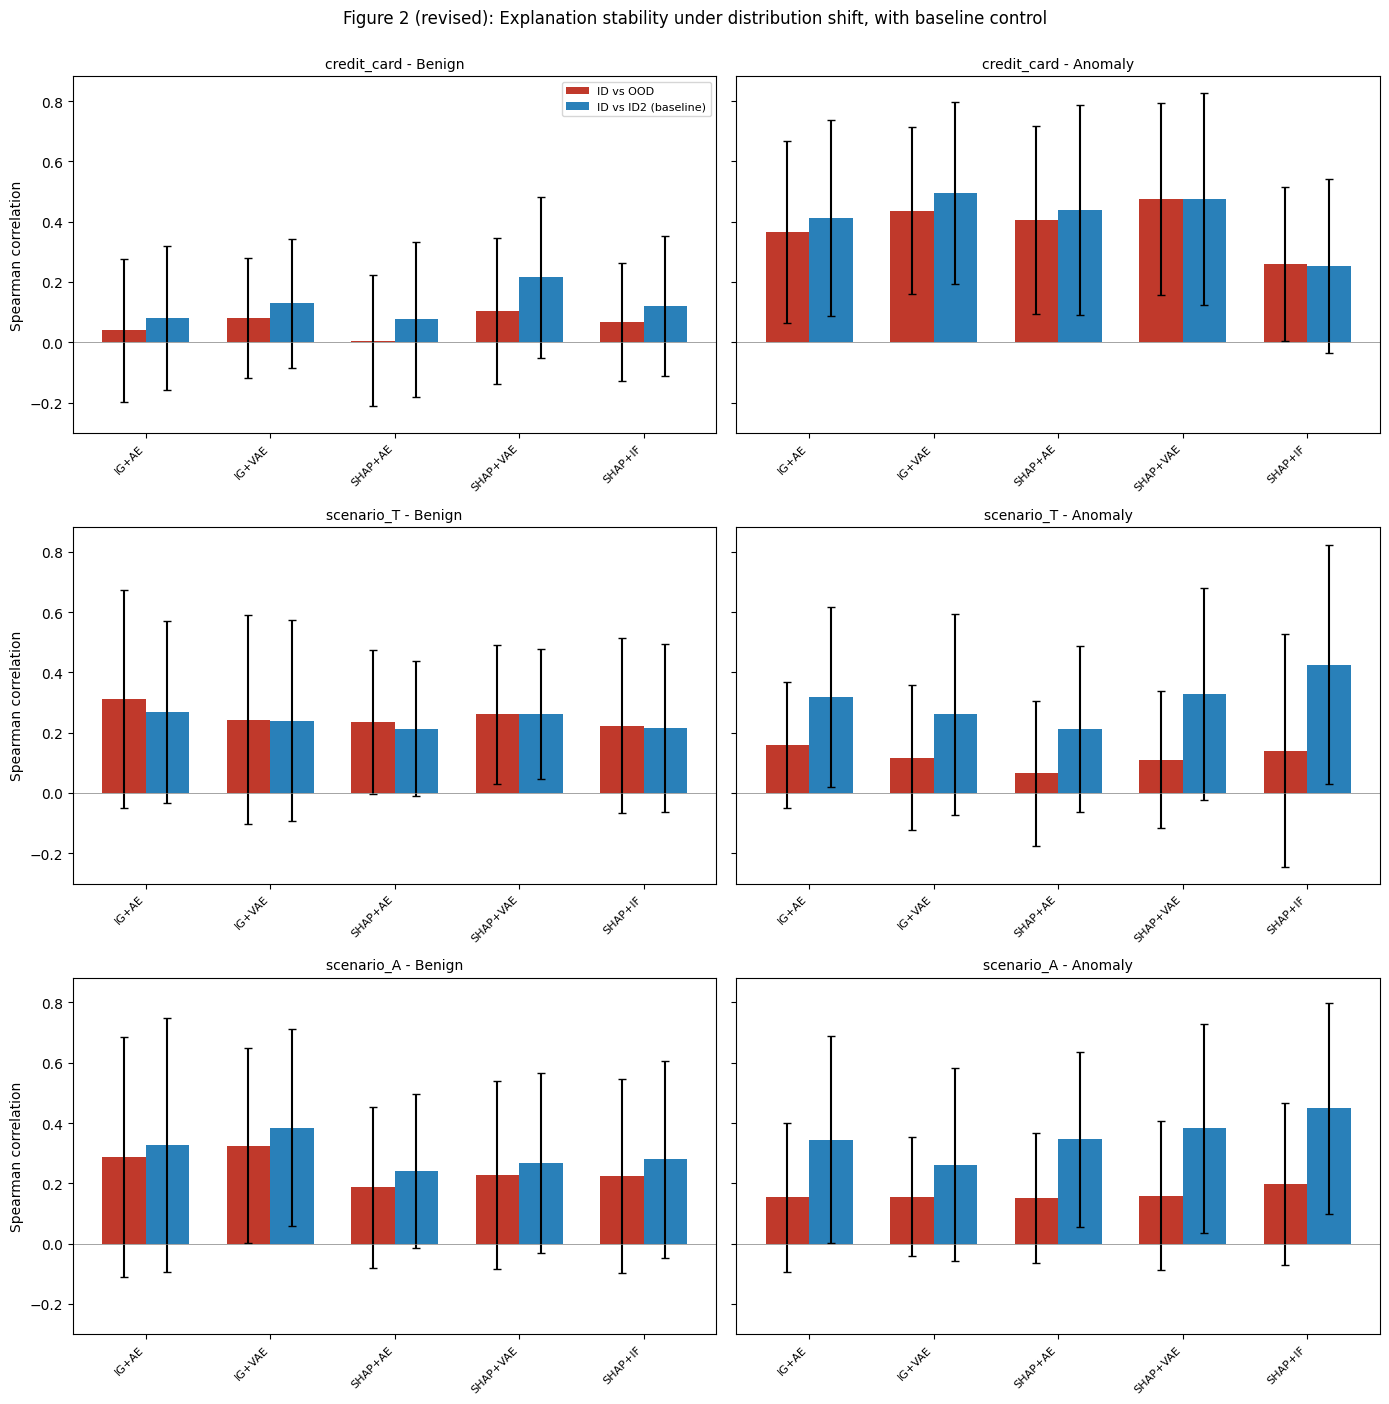

Saved figure2_stability_revised.png


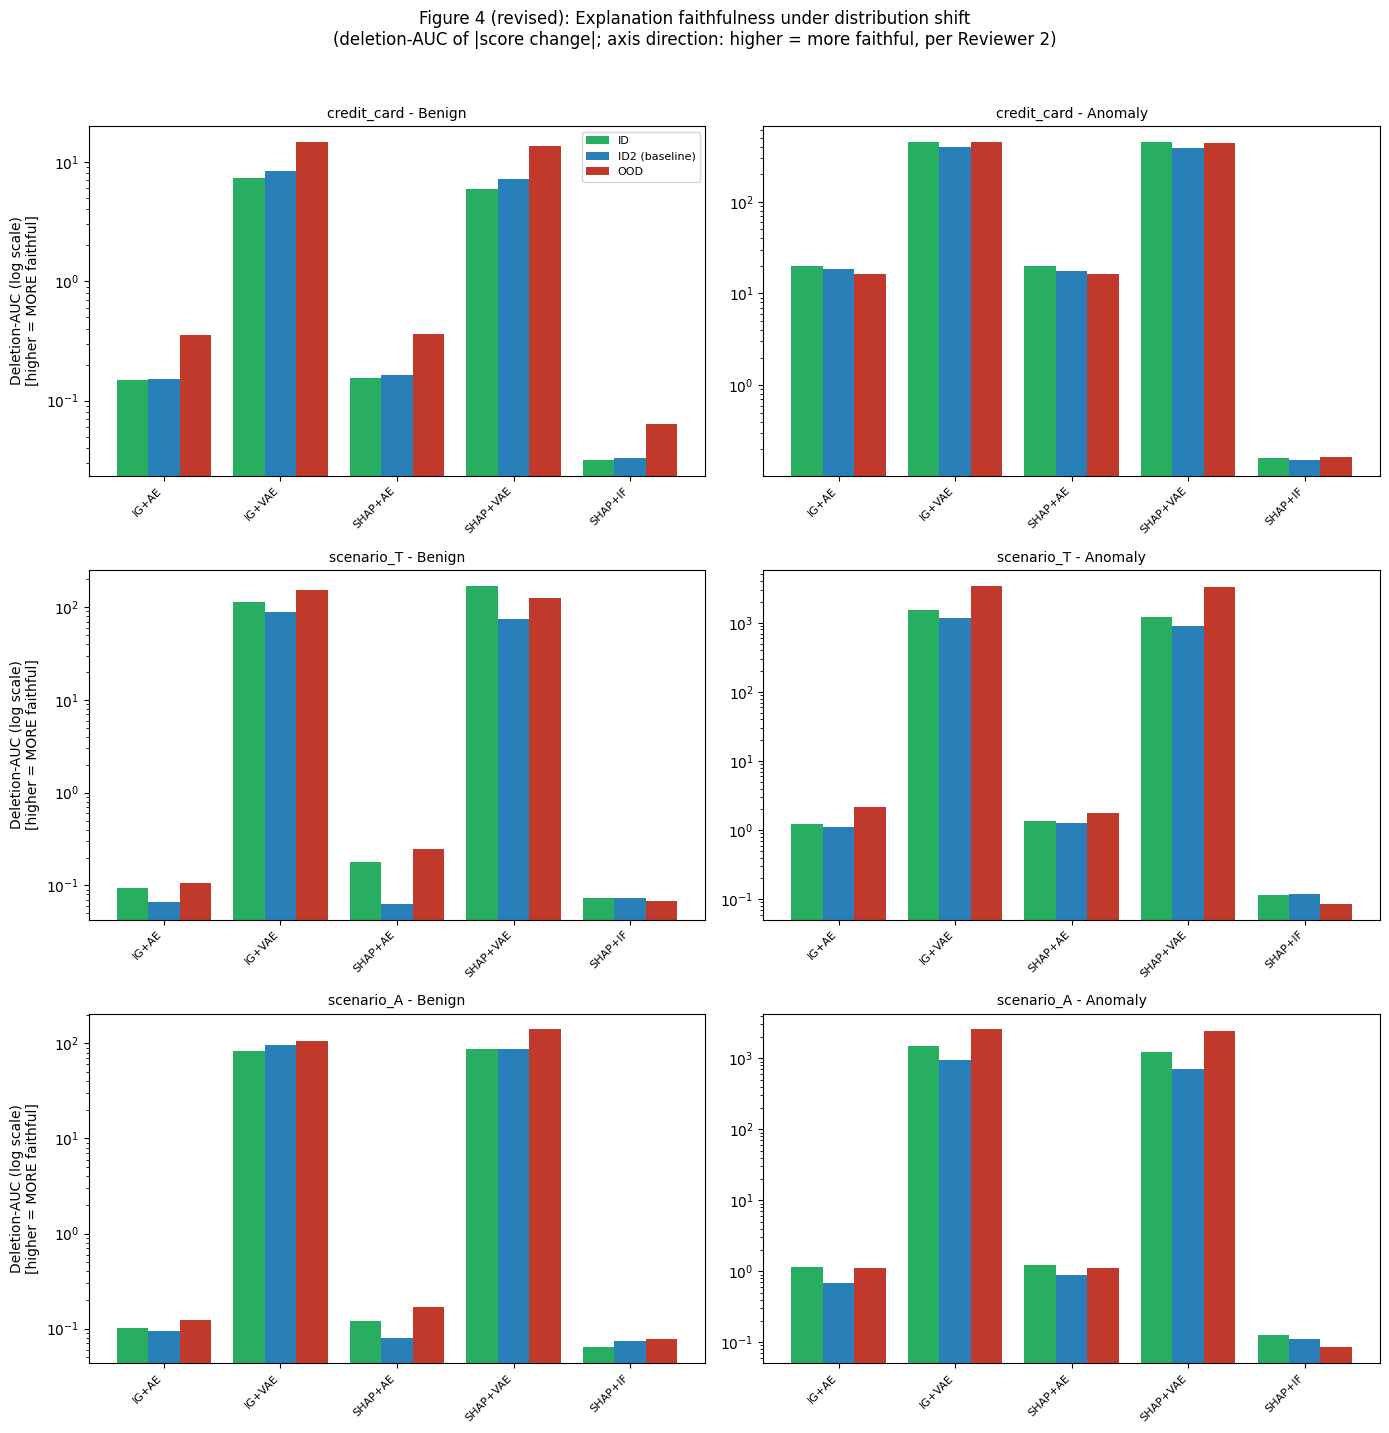

Saved figure4_faithfulness_revised.png


In [5]:
import matplotlib.pyplot as plt
import numpy as np

# ---- Table 3: significance summary ----
table3 = all_primary.copy()
table3['Metric'] = table3['family'].map({'stability': 'Stability (Spearman)', 'faithfulness': 'Faithfulness (Deletion-AUC)'})
table3['Class'] = table3['class'].map({0: 'Benign', 1: 'Anomaly'})
table3_out = table3[['dataset','Metric','method','model','Class','median_ood','median_id2',
                      'p_value','p_adj_BH','significant_FDR05','effect_size_rb']].rename(columns={
    'dataset':'Dataset','method':'XAI Method','model':'Model',
    'median_ood':'Median (OOD)','median_id2':'Median (ID2)',
    'p_value':'p-value','p_adj_BH':'p-adj (BH-FDR)','significant_FDR05':'Significant (q<0.05)',
    'effect_size_rb':'Effect size (rank-biserial)'
})
table3_out['XAI Method'] = table3_out['XAI Method'].str.upper()
table3_out['Model'] = table3_out['Model'].str.upper()
print("=== TABLE 3 (new): Statistical significance of shift-driven degradation vs ID2 baseline ===")
print(table3_out.to_string(index=False))
table3_out.to_csv('/kaggle/working/table3_significance.csv', index=False)

# ---- Figure 2 (revised): stability, ID-vs-OOD vs ID-vs-ID2, all models/methods ----
fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharey=True)
datasets_order = ['credit_card', 'scenario_T', 'scenario_A']
class_order = [0, 1]
for i, ds in enumerate(datasets_order):
    for j, cls in enumerate(class_order):
        ax = axes[i, j]
        sub = stability_df[(stability_df.dataset==ds) & (stability_df['class']==cls)]
        combos = sub[['method','model']].drop_duplicates()
        labels = [f"{m.upper()}+{mo.upper()}" for m, mo in zip(combos.method, combos.model)]
        ood_vals, ood_err, id2_vals, id2_err = [], [], [], []
        for m, mo in zip(combos.method, combos.model):
            r_ood = sub[(sub.method==m)&(sub.model==mo)&(sub.comparison=='ID_vs_OOD')].iloc[0]
            r_id2 = sub[(sub.method==m)&(sub.model==mo)&(sub.comparison=='ID_vs_ID2')].iloc[0]
            ood_vals.append(r_ood.mean_spearman); ood_err.append(r_ood.std_spearman)
            id2_vals.append(r_id2.mean_spearman); id2_err.append(r_id2.std_spearman)
        x = np.arange(len(labels)); w = 0.35
        ax.bar(x - w/2, ood_vals, w, yerr=ood_err, capsize=3, label='ID vs OOD', color='#c0392b')
        ax.bar(x + w/2, id2_vals, w, yerr=id2_err, capsize=3, label='ID vs ID2 (baseline)', color='#2980b9')
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
        ax.set_title(f"{ds} - {'Benign' if cls==0 else 'Anomaly'}", fontsize=10)
        ax.axhline(0, color='gray', linewidth=0.5)
        if j == 0:
            ax.set_ylabel('Spearman correlation')
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
plt.suptitle('Figure 2 (revised): Explanation stability under distribution shift, with baseline control', y=1.0)
plt.tight_layout()
plt.savefig('/kaggle/working/figure2_stability_revised.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved figure2_stability_revised.png")

# ---- Figure 4 (revised): faithfulness, explicit axis direction, log-scale (huge cross-model range) ----
fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=False)
for i, ds in enumerate(datasets_order):
    for j, cls in enumerate(class_order):
        ax = axes[i, j]
        sub = faithfulness_df[(faithfulness_df.dataset==ds) & (faithfulness_df['class']==cls)]
        combos = sub[['method','model']].drop_duplicates()
        labels = [f"{m.upper()}+{mo.upper()}" for m, mo in zip(combos.method, combos.model)]
        id_vals, id2_vals, ood_vals = [], [], []
        for m, mo in zip(combos.method, combos.model):
            r_id = sub[(sub.method==m)&(sub.model==mo)&(sub.split=='id')].iloc[0]
            r_id2 = sub[(sub.method==m)&(sub.model==mo)&(sub.split=='id2')].iloc[0]
            r_ood = sub[(sub.method==m)&(sub.model==mo)&(sub.split=='ood')].iloc[0]
            id_vals.append(r_id.mean_auc); id2_vals.append(r_id2.mean_auc); ood_vals.append(r_ood.mean_auc)
        x = np.arange(len(labels)); w = 0.27
        ax.bar(x - w, id_vals, w, label='ID', color='#27ae60')
        ax.bar(x, id2_vals, w, label='ID2 (baseline)', color='#2980b9')
        ax.bar(x + w, ood_vals, w, label='OOD', color='#c0392b')
        ax.set_yscale('log')
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
        ax.set_title(f"{ds} - {'Benign' if cls==0 else 'Anomaly'}", fontsize=10)
        if j == 0:
            ax.set_ylabel('Deletion-AUC (log scale)\n[higher = MORE faithful]')
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
plt.suptitle('Figure 4 (revised): Explanation faithfulness under distribution shift\n'
             '(deletion-AUC of |score change|; axis direction: higher = more faithful, per Reviewer 2)', y=1.02)
plt.tight_layout()
plt.savefig('/kaggle/working/figure4_faithfulness_revised.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved figure4_faithfulness_revised.png")

In [6]:
import zipfile, os

zip_path = '/kaggle/working/nb8_complete.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in ['table1_stability_revised.csv', 'table2_faithfulness.csv', 'table3_significance.csv',
                  'figure2_stability_revised.png', 'figure4_faithfulness_revised.png']:
        zf.write(f'/kaggle/working/{fname}', fname)

for f in ['table1_stability_revised.csv', 'table2_faithfulness.csv', 'table3_significance.csv',
          'figure2_stability_revised.png', 'figure4_faithfulness_revised.png', 'nb8_complete.zip']:
    print(f, os.path.getsize(f'/kaggle/working/{f}'), 'bytes')

table1_stability_revised.csv 2034 bytes
table2_faithfulness.csv 2386 bytes
table3_significance.csv 9383 bytes
figure2_stability_revised.png 148651 bytes
figure4_faithfulness_revised.png 185577 bytes
nb8_complete.zip 261352 bytes
